In [77]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [78]:
# Loan the dataset
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')

In [79]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

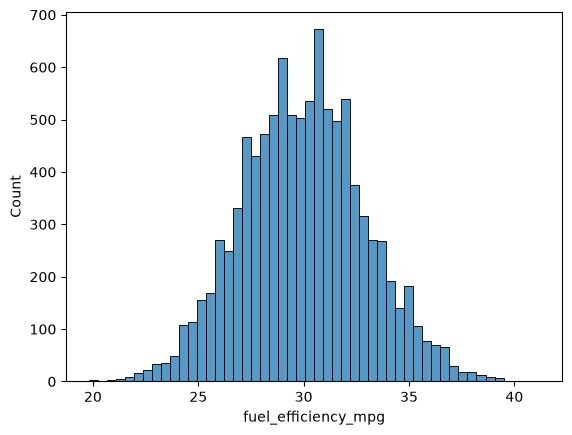

In [80]:
sns.histplot(df.fuel_efficiency_mpg, bins=50)

In [81]:
column_base = [
    'engine_displacement',
    'horsepower',
    'vehicle_weight',
    'model_year',
    'fuel_efficiency_mpg'
]

In [82]:
df = df[column_base]

In [83]:
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


In [ ]:
# 1. Missing values

In [84]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [65]:
# 2. Median for horsepower

df.horsepower.median()

np.float64(254.0)

In [66]:
df.describe()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
count,10000.000000,9123.000000,10000.000000,10000.000000,10000.000000
mean,2268.807000,254.446016,4286.754000,1999.549500,29.997700
std,183.447355,22.844613,266.212491,14.207925,2.930245
min,1590.000000,171.000000,3320.000000,1975.000000,19.800000
25%,2150.000000,239.000000,4110.000000,1987.000000,28.000000
50%,2270.000000,254.000000,4280.000000,2000.000000,30.000000
75%,2390.000000,270.000000,4470.000000,2012.000000,31.900000
max,3110.000000,334.000000,5460.000000,2024.000000,41.200000


In [ ]:
# Prepare and split the dataset

# Setting up the validation framework
# shuffling and filtering the dataset
# Calculating the sizes of the parts => 60 - 20 - 20

In [16]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [17]:
df_train.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
6252,1900,239.0,3790,2015,32.5
4684,2000,224.0,4380,1992,29.1
1731,2330,286.0,4090,2022,34.1
4742,2300,NaN,4150,1997,30.6
4521,2340,269.0,4400,2001,30.7


In [18]:
# Resetting the index

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [19]:
df_train.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,1900,239.0,3790,2015,32.5
1,2000,224.0,4380,1992,29.1
2,2330,286.0,4090,2022,34.1
3,2300,NaN,4150,1997,30.6
4,2340,269.0,4400,2001,30.7


In [20]:
# Preparing y and removing fuel_efficiency_mpg

y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [21]:
y_train

array([32.5, 29.1, 34.1, ..., 27.7, 31.6, 28. ], shape=(6000,))

In [67]:
# Handling missing values and preparing the feature matrix

# Fill with 0 value
def prepare_X_Fill0(data):
    df_num = data.fillna(0)
    X = df_num.values
    return X

In [23]:
# Fill with mean value

def prepare_X_Mean(df):
    median = df['horsepower'].median()
    df['horsepower'] = df.horsepower.fillna(median, inplace=True)
    X = df.values
    return X

In [48]:
# Linear regression model

def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [49]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return round(np.sqrt(mse), 3)

In [22]:
X_train = prepare_X_Fill0(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X_Fill0(df_val)
y_pred = w0 + X_val.dot(w)

rmse(y_val, y_pred)

np.float64(2.205)

In [23]:
X_train = prepare_X_Mean(df_train)
w0, w = train_linear_regression(X_train, y_train)

# X_val = prepare_X_Fill0(df_val)
y_pred = w0 + df_val.dot(w)

rmse(y_val, y_pred)

/var/folders/04/vl3jr1ks0897h39z7nrwl_8m0000gn/T/ipykernel_19268/1473509494.py:5: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['horsepower'] = df.horsepower.fillna(median, inplace=True)


np.float64(2.186)

In [1]:
print("123")

123


In [ ]:
# Regularization

In [70]:
def train_linear_regression_reg(X, y, r):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])
    
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [71]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return round(np.sqrt(mse), 4)

In [ ]:
# Tuning the model

In [29]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    X_train = prepare_X_Fill0(df_train)
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    X_val = prepare_X_Fill0(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    print(r, w0, score)

0 -153.8849618823488 2.2053
0.01 -148.30921244069182 2.2058
0.1 -111.8387103928716 2.2241
1 -32.331865965012575 2.3492
5 -7.772852209986799 2.4094
10 -3.987116416021029 2.4195
100 -0.4082196488466061 2.4292


In [ ]:
# prepare and split the dataset and shuffling

In [ ]:
def data_split_shuffle(df):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test
    
    scores_list = []

    for sv in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
        np.random.seed(sv)
        idx = np.arange(n)
        np.random.shuffle(idx)

        df_train = df.iloc[idx[:n_train]]
        df_val = df.iloc[idx[n_train:n_train + n_val]]
        df_test = df.iloc[idx[n_train + n_val:]]
        
        # Resetting the index
        df_train = df_train.reset_index(drop=True)
        df_val = df_val.reset_index(drop=True)
        df_test = df_test.reset_index(drop=True)
        
        # Preparing y and removing fuel_efficiency_mpg
        y_train = df_train.fuel_efficiency_mpg.values
        y_val = df_val.fuel_efficiency_mpg.values
        y_test = df_test.fuel_efficiency_mpg.values

        del df_train['fuel_efficiency_mpg']
        del df_val['fuel_efficiency_mpg']
        del df_test['fuel_efficiency_mpg']
        
        #
        X_train = prepare_X_Fill0(df_train)
        w0, w = train_linear_regression(X_train, y_train)

        X_val = prepare_X_Fill0(df_val)
        y_pred = w0 + X_val.dot(w)
        score = rmse(y_val, y_pred)
        
        print(f"Seed {sv} -> w0: {w0:.4f}, RMSE Score: {score:.4f}")
        
        scores_list.append(score)
        
        # store the score so that we can find the standard deviation of all the score values.
        
    scores_array = np.array(scores_list)
       
    full_stan_dev = np.std(scores_array)
    sample_stan_dev = np.std(scores_array, ddof=1)
    
    print("\n--- Final Results ---")
    print(f"All Scores: {scores_list}")
    print(f"Population Std Dev: {full_stan_dev:.4f}")
    print(f"Sample Std Dev: {sample_stan_dev:.4f}")
    

In [55]:
data_split_shuffle(df)

Seed 0 -> w0: -150.4289, RMSE Score: 2.2390
Seed 1 -> w0: -151.6123, RMSE Score: 2.2020
Seed 2 -> w0: -152.8407, RMSE Score: 2.1630
Seed 3 -> w0: -152.3330, RMSE Score: 2.2040
Seed 4 -> w0: -158.8886, RMSE Score: 2.2020
Seed 5 -> w0: -151.8574, RMSE Score: 2.2460
Seed 6 -> w0: -154.3718, RMSE Score: 2.2700
Seed 7 -> w0: -155.0184, RMSE Score: 2.1910
Seed 8 -> w0: -150.4382, RMSE Score: 2.2170
Seed 9 -> w0: -154.3601, RMSE Score: 2.2070

--- Final Results ---
All Scores: [np.float64(2.239), np.float64(2.202), np.float64(2.163), np.float64(2.204), np.float64(2.202), np.float64(2.246), np.float64(2.27), np.float64(2.191), np.float64(2.217), np.float64(2.207)]
Population Std Dev: 0.0289
Sample Std Dev: 0.0305


In [86]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

# Resetting the index
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Preparing y and removing fuel_efficiency_mpg
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']


df_full_train = pd.concat([df_train, df_val], axis=0).reset_index(drop=True)

# 2. Combine the Target arrays
y_full_train = np.concatenate([y_train, y_val])

In [87]:
X_train = prepare_X_Fill0(df_full_train)
w0, w = train_linear_regression_reg(X_train, y_full_train, r=0.001)

X_val = prepare_X_Fill0(df_test)
y_pred = w0 + X_val.dot(w)
score = rmse(y_test, y_pred)

print(r, w0, score)

100 -152.37535772490966 2.2358
